Attention : plusieurs correspondances restent proches. Verifie les crops ci-dessous.
Detection par cercles Hough : 6 piece(s) trouvee(s)
Centre=(654, 1190), diametre=324.9 px, saturation=100 : 10 TWD
Centre=(872, 699), diametre=265.4 px, saturation=133 : 1 TWD
Centre=(1166, 1442), diametre=358.0 px, saturation=219 : 50 TWD
Centre=(1404, 679), diametre=345.6 px, saturation=160 : 50 TWD
Centre=(1359, 1874), diametre=268.2 px, saturation=151 : 1 TWD
Centre=(748, 1975), diametre=240.5 px, saturation=211 : 1 TWD
Erreur moyenne d identification : 3.6%


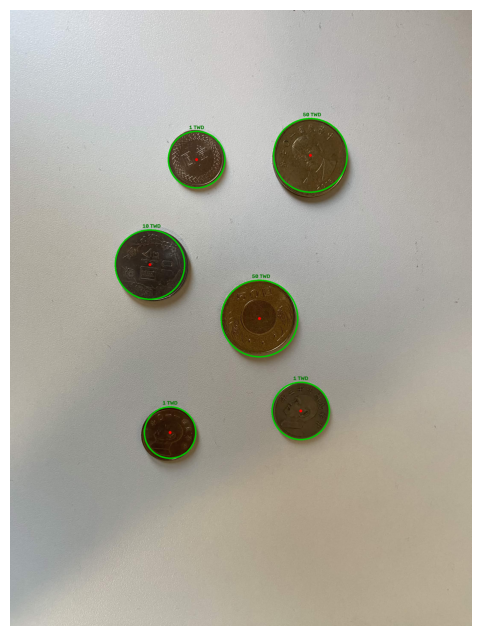

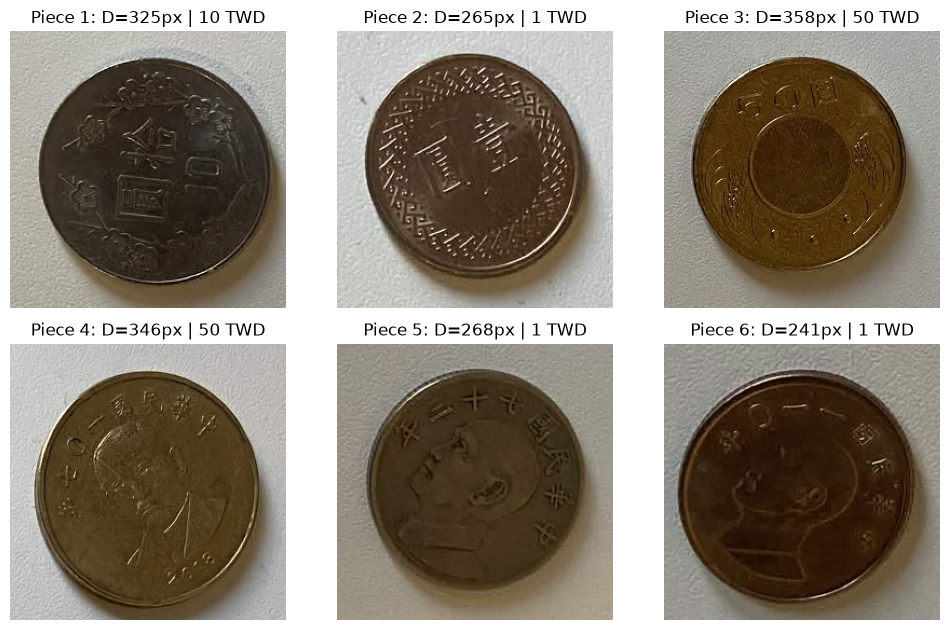


Total detecte : 113 TWD
Equivalent en EUR : 3.06 EUR
Equivalent en euros : 3.06 EUR
Taux mis a jour le : Thu, 05 Nov 2026 00:02:31 +0000


In [60]:
import json
from itertools import combinations
from urllib.request import urlopen

import cv2
import matplotlib.pyplot as plt
import numpy as np

# Photo a analyser. Les dimensions sont normalisees avant la detection.
chemin_image = './data/IMG_5694.jpg'
devise_souhaitee = 'EUR'

# Diametres des pieces courantes en circulation (millimetres).
diametres_twd_mm = {1: 20.0, 5: 22.0, 10: 26.0, 50: 28.0}

image_couleur = cv2.imread(chemin_image)
if image_couleur is None:
    raise FileNotFoundError(f'Photo introuvable : {chemin_image}. Verifie le nom et le dossier data.')
image_gris = cv2.cvtColor(image_couleur, cv2.COLOR_BGR2GRAY)
image_hsv = cv2.cvtColor(image_couleur, cv2.COLOR_BGR2HSV)

hauteur_originale, largeur_originale = image_gris.shape
facteur_redimensionnement = 1000 / max(image_gris.shape)
image_reduite = cv2.resize(
    image_gris, None, fx=facteur_redimensionnement, fy=facteur_redimensionnement,
    interpolation=cv2.INTER_AREA if facteur_redimensionnement < 1 else cv2.INTER_CUBIC
)
image_contraste = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(image_reduite)
image_floue = cv2.GaussianBlur(image_contraste, (9, 9), 2)
cote_court = min(image_floue.shape)

# Detection Hough adaptee a la taille de l'image.
cercles_hough = cv2.HoughCircles(
    image_floue,
    cv2.HOUGH_GRADIENT,
    dp=1.2,
    minDist=max(20, round(cote_court * 0.12)),
    param1=100,
    param2=50,
    minRadius=max(8, round(cote_court * 0.04)),
    maxRadius=round(cote_court * 0.25),
)
pieces_hough = []
if cercles_hough is not None:
    for x, y, rayon in cercles_hough[0]:
        rayon = float(rayon)
        pieces_hough.append({
            'centre': (float(x), float(y)),
            'rayon': rayon,
            'axes': (rayon, rayon),
            'angle': 0.0,
            'methode': 'cercle',
        })

# Les contours elliptiques recuperent aussi les pieces vues en biais.
bords = cv2.Canny(image_floue, 35, 100)
contours, _ = cv2.findContours(bords, cv2.RETR_LIST, cv2.CHAIN_APPROX_NONE)
candidats_ellipses = []
for contour in contours:
    if len(contour) < 30:
        continue
    aire = cv2.contourArea(contour)
    if aire < cote_court * cote_court * 0.0004:
        continue
    perimetre = cv2.arcLength(contour, True)
    if perimetre == 0:
        continue
    circularite = 4 * np.pi * aire / (perimetre * perimetre)
    (x, y), (axe_1, axe_2), angle = cv2.fitEllipse(contour)
    grand_axe, petit_axe = max(axe_1, axe_2), min(axe_1, axe_2)
    if petit_axe < cote_court * 0.035 or grand_axe > cote_court * 0.7:
        continue
    if petit_axe / grand_axe < 0.55 or circularite < 0.45:
        continue
    rayon = float(np.sqrt(axe_1 * axe_2) / 2)
    candidats_ellipses.append({
        'centre': (float(x), float(y)),
        'rayon': rayon,
        'axes': (float(axe_1 / 2), float(axe_2 / 2)),
        'angle': float(angle),
        'methode': 'ellipse',
    })

pieces_ellipses = []
for piece in sorted(candidats_ellipses, key=lambda item: item['rayon'], reverse=True):
    x, y = piece['centre']
    if all(
        np.hypot(x - autre['centre'][0], y - autre['centre'][1])
        > min(piece['rayon'], autre['rayon']) * 0.45
        for autre in pieces_ellipses
    ):
        pieces_ellipses.append(piece)

# Garde la methode qui trouve le plus de pieces plausibles pour cette image.
if len(pieces_ellipses) > len(pieces_hough):
    pieces_detectees = pieces_ellipses
    methode_detection = 'contours elliptiques'
else:
    pieces_detectees = pieces_hough
    methode_detection = 'cercles Hough'
if not pieces_detectees:
    raise ValueError('Aucune piece detectee. Essaie une photo nette, prise de dessus.')

# Repasse chaque mesure a l'echelle originale et mesure aussi sa couleur.
for piece in pieces_detectees:
    piece['centre'] = tuple(coord / facteur_redimensionnement for coord in piece['centre'])
    piece['rayon'] /= facteur_redimensionnement
    piece['axes'] = tuple(axe / facteur_redimensionnement for axe in piece['axes'])
    x, y = piece['centre']
    marge = max(piece['axes'])
    piece['partielle'] = (
        x - marge < 0 or y - marge < 0
        or x + marge >= largeur_originale or y + marge >= hauteur_originale
    )
    rayon_couleur = max(2, int(piece['rayon'] * 0.55))
    x0, x1 = max(0, int(x) - rayon_couleur), min(largeur_originale, int(x) + rayon_couleur)
    y0, y1 = max(0, int(y) - rayon_couleur), min(hauteur_originale, int(y) + rayon_couleur)
    zone_hsv = image_hsv[y0:y1, x0:x1]
    yy, xx = np.ogrid[y0:y1, x0:x1]
    masque_piece = (xx - x) ** 2 + (yy - y) ** 2 <= rayon_couleur ** 2
    pixels_saturation = zone_hsv[:, :, 1][masque_piece]
    piece['saturation'] = float(np.median(pixels_saturation)) if pixels_saturation.size else float('nan')

pieces_completes = [piece for piece in pieces_detectees if not piece['partielle']]
if len(pieces_completes) < 2:
    raise ValueError(
        'Il faut au moins deux pieces entieres de tailles differentes pour comparer '
        'leurs diametres. Une piece coupee par le bord ne peut pas etre mesuree correctement.'
    )


def classer_pieces(pieces, references):
    rayons = np.array([piece['rayon'] for piece in pieces], dtype=float)
    saturations = np.array([piece.get('saturation', np.nan) for piece in pieces], dtype=float)
    valeurs_connues = list(references)
    solutions = {}
    for nombre in range(2, min(len(valeurs_connues), len(rayons)) + 1):
        for sous_ensemble in combinations(valeurs_connues, nombre):
            diametres = np.array([references[valeur] for valeur in sous_ensemble])
            valeurs_array = np.array(sous_ensemble)
            penalites_couleur = np.zeros((len(pieces), nombre))
            for i, saturation in enumerate(saturations):
                if not np.isfinite(saturation):
                    continue
                for j, valeur in enumerate(valeurs_array):
                    if valeur in (5, 10) and saturation > 100:
                        penalites_couleur[i, j] = 0.06
                    elif valeur == 50 and saturation < 100:
                        penalites_couleur[i, j] = 0.06
            for rayon in rayons:
                for diametre in diametres:
                    echelle = rayon / diametre
                    for _ in range(5):
                        erreurs = np.abs(rayons[:, None] - echelle * diametres) / (echelle * diametres)
                        indices = np.argmin(erreurs + penalites_couleur, axis=1)
                        valides = erreurs[np.arange(len(rayons)), indices] < 0.14
                        if len(set(valeurs_array[indices[valides]].tolist())) < 2:
                            break
                        echelle = float(np.median(rayons[valides] / diametres[indices[valides]]))
                    erreurs = np.abs(rayons[:, None] - echelle * diametres) / (echelle * diametres)
                    indices = np.argmin(erreurs + penalites_couleur, axis=1)
                    ecarts = erreurs[np.arange(len(rayons)), indices]
                    valides = ecarts < 0.14
                    classes = set(valeurs_array[indices[valides]].tolist())
                    if len(classes) < 2:
                        continue
                    affectations = tuple(
                        int(valeurs_array[indice]) if valide else None
                        for indice, valide in zip(indices, valides)
                    )
                    score = float(
                        np.mean(ecarts[valides] + penalites_couleur[np.arange(len(rayons))[valides], indices[valides]])
                        + 0.10 * (1 - np.mean(valides))
                        + 0.002 * (len(classes) - 2)
                    )
                    if affectations not in solutions or score < solutions[affectations][0]:
                        solutions[affectations] = (score, echelle, affectations)
    resultats = sorted(solutions.values(), key=lambda resultat: resultat[0])
    if not resultats:
        raise ValueError(
            'Les tailles detectees ne correspondent pas assez au catalogue TWD. '
            'Prends la photo de dessus avec les pieces entieres et separees.'
        )
    if resultats[0][0] > 0.08:
        raise ValueError('La correspondance des tailles et couleurs est trop incertaine.')
    return resultats


resultats = classer_pieces(pieces_completes, diametres_twd_mm)
meilleure_erreur, echelle_mm, valeurs_par_piece = resultats[0]
if len(resultats) > 1 and resultats[1][0] - meilleure_erreur < 0.01:
    print('Attention : plusieurs correspondances restent proches. Verifie les crops ci-dessous.')

# Test minimal : deux tailles seules doivent etre reconnues par comparaison.
pieces_test = [{'rayon': 20.0}, {'rayon': 28.0}]
assert classer_pieces(pieces_test, diametres_twd_mm)[0][2] == (1, 50)

image_resultat = cv2.cvtColor(image_couleur, cv2.COLOR_BGR2RGB)
total_twd = 0
pieces_non_classees = 0
print(f'Detection par {methode_detection} : {len(pieces_detectees)} piece(s) trouvee(s)')
for piece in pieces_detectees:
    x, y = (int(coord) for coord in piece['centre'])
    axes = tuple(int(axe) for axe in piece['axes'])
    if piece['methode'] == 'ellipse':
        cv2.ellipse(image_resultat, (x, y), axes, piece['angle'], 0, 360, (0, 200, 0), 6)
    else:
        cv2.circle(image_resultat, (x, y), int(piece['rayon']), (0, 200, 0), 6)
    cv2.circle(image_resultat, (x, y), 7, (255, 0, 0), -1)
    if piece['partielle']:
        etiquette = 'partielle'
        pieces_non_classees += 1
    else:
        indice = pieces_completes.index(piece)
        valeur = valeurs_par_piece[indice]
        if valeur is None:
            etiquette = 'inconnue'
            pieces_non_classees += 1
        else:
            etiquette = f'{valeur} TWD'
            total_twd += valeur
    piece['etiquette'] = etiquette
    cv2.putText(
        image_resultat, etiquette, (x - 35, y - int(piece['rayon']) - 10),
        cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 120, 0), 2
    )
    print(
        f'Centre=({x}, {y}), diametre={2 * piece["rayon"]:.1f} px, '
        f'saturation={piece["saturation"]:.0f} : {etiquette}'
    )

print(f'Erreur moyenne d identification : {meilleure_erreur:.1%}')
if pieces_non_classees:
    print(f'Attention : {pieces_non_classees} piece(s) partielle(s) ou non classee(s), total incomplet.')

plt.figure(figsize=(14, 8))
plt.imshow(image_resultat)
plt.axis('off')
plt.show()

# Affiche chaque piece dans un crop carre de meme taille, sans modifier son diametre mesure.
colonnes = 3
lignes = int(np.ceil(len(pieces_detectees) / colonnes))
figure, axes = plt.subplots(lignes, colonnes, figsize=(10, 3.2 * lignes))
axes = np.array(axes).reshape(-1)
for indice, piece in enumerate(pieces_detectees):
    x, y = (int(coord) for coord in piece['centre'])
    cote_crop = max(20, int(max(piece['axes']) * 2.5))
    x0, y0 = x - cote_crop // 2, y - cote_crop // 2
    crop_carre = np.zeros((cote_crop, cote_crop, 3), dtype=np.uint8)
    sx0, sy0 = max(0, x0), max(0, y0)
    sx1, sy1 = min(largeur_originale, x0 + cote_crop), min(hauteur_originale, y0 + cote_crop)
    crop_carre[sy0 - y0:sy1 - y0, sx0 - x0:sx1 - x0] = image_couleur[sy0:sy1, sx0:sx1]
    crop_normalise = cv2.resize(crop_carre, (256, 256), interpolation=cv2.INTER_CUBIC)
    axes[indice].imshow(cv2.cvtColor(crop_normalise, cv2.COLOR_BGR2RGB))
    axes[indice].set_title(f'Piece {indice + 1}: D={2 * piece["rayon"]:.0f}px | {piece["etiquette"]}')
    axes[indice].axis('off')
for axe in axes[len(pieces_detectees):]:
    axe.axis('off')
figure.tight_layout()
plt.show()

# Taux du jour : source TWD, avec conversion vers la devise choisie et vers EUR.
url_taux = 'https://open.er-api.com/v6/latest/TWD'
with urlopen(url_taux, timeout=15) as reponse:
    donnees_taux = json.loads(reponse.read().decode('utf-8'))
if donnees_taux.get('result') != 'success':
    raise RuntimeError('Le service de taux de change n a pas renvoye de taux valides.')

taux = donnees_taux['rates']
devise_souhaitee = devise_souhaitee.strip().upper()
if devise_souhaitee not in taux:
    raise ValueError(f'Devise non disponible : {devise_souhaitee}')

montant_devise = total_twd * taux[devise_souhaitee]
montant_eur = total_twd * taux['EUR']
print(f'\nTotal detecte : {total_twd} TWD')
print(f'Equivalent en {devise_souhaitee} : {montant_devise:.2f} {devise_souhaitee}')
print(f'Equivalent en euros : {montant_eur:.2f} EUR')
print(f"Taux mis a jour le : {donnees_taux.get('time_last_update_utc', 'date inconnue')}")